# 02简单线性回归
> **简单 = 只有 1 个自变量 x，预测 1 个连续因变量 y**，是所有回归、深度学习的基础

## 一句话定义
寻找一条直线 $\hat y = w_1 x + w_0$，尽可能贴近所有样本点；用一个特征 $x$ 去预测连续值 $y$。

- $\hat y$：预测值（读 y hat）
- $w_1$：斜率（权重 weight），x 每增加 1 单位，y 平均变化多少
- $w_0$：截距（偏置 bias），x=0 时预测出来的 y 值

例子：学习时长 x → 考试分数 y；房子面积 x → 房价 y

## 核心：最小二乘法 OLS (Ordinary Least Squares)
目标：让所有样本真实值 $y$ 和线上预测值 $\hat y$ 的误差平方总和最小

损失函数（均方误差 MSE）：
$$
J(w_0,w_1)=\frac{1}{n}\sum_{i=1}^n (y_i-\hat y_i)^2=\frac{1}{n}\sum_{i=1}^n (y_i-(w_1 x_i+w_0))^2
$$
平方的好处：正负误差不会抵消，放大离群点的惩罚。

直接闭式求解公式（不用迭代，直接算出最优 $w_1,w_0$）：
$$
w_1=\frac{\sum_{i=1}^n(x_i-\bar x)(y_i-\bar y)}{\sum_{i=1}^n(x_i-\bar x)^2},\quad w_0=\bar y - w_1\bar x
$$
$\bar x,\bar y$ 是 x、y 的均值

✅ 区分：后面会学梯度下降是迭代慢慢逼近；最小二乘是数学直接解方程一步算出最优参数。

## 模型假设
1. **线性**：x 和 y 本身存在线性趋势
2. **误差独立**：样本之家噪声互不影响
3. **误差同方差**：不管x取大取小，离散程度差不多
4. **误差正态分布**：误差服从正态分布
> ⚠️ 相关 ≠ 因果！只是拟合相关性，不能直接证明 x 导致 y 变化

## 评价指标：$R^2$ 决定系数

$$
R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}
$$

- $R^2 \in [0,1]$
- 越接近 1：直线拟合效果越好
- 接近 0：这条直线还不如直接拿 $y$ 的平均值去猜


## Python实现

斜率w1=5.30, 截距w0=35.15
公式：y = 5.30 * x + 35.15
R²=-0.928


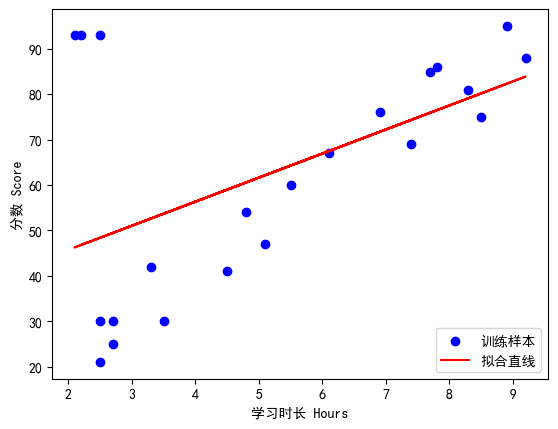

In [3]:
# sklearn调用简单线性回归（修复警告 + 中文正常显示）
import pandas as pd               # 表格处理库，用来读取csv数据集
import numpy as np                # 数值计算库，机器学习常用配套库
import matplotlib.pyplot as plt   # 绘图库，绘制散点图和回归直线
from sklearn.model_selection import train_test_split  # 数据集划分工具：训练集/测试集
from sklearn.linear_model import LinearRegression     # 简单线性回归模型（底层OLS最小二乘）
from sklearn.metrics import r2_score                  # R²决定系数，回归评估指标
import warnings                     # python内置警告控制模块

# ---------------------- 1. 关闭sklearn相关警告 ----------------------
warnings.filterwarnings("ignore")
# 作用：屏蔽无关的格式、版本、shape警告；学习实验可用，正式项目不建议全局忽略警告

# ---------------------- 2. 解决matplotlib中文乱码 + 负号显示异常 ----------------------
plt.rcParams["font.sans-serif"] = ["SimHei"]  # Windows使用黑体；Mac改成 "Arial Unicode MS"
plt.rcParams["axes.unicode_minus"] = False    # 关闭负号自动替换，防止负号显示成方框

# 1. 读数据，这里经典数据集：学习小时数 -> 分数
df = pd.read_csv("./studentscores.csv") # 读取本地csv文件，加载为DataFrame表格
X = df[["Hours"]]  # ⚠️双层方括号，输出二维DataFrame，满足sklearn输入要求，避免一维警告
y = df["Scores"]   # 标签：考试分数，一维Series

# 2. 划分训练集、测试集
# test_size=0.2：20%数据作为测试集，80%用来训练模型
# random_state=0：固定随机种子，每次运行划分出来的数据完全一致，方便复现实验
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 3. 训练简单线性回归
reg = LinearRegression()        # 实例化线性回归模型对象
reg.fit(X_train, y_train)       # fit()：喂入训练数据，内部用最小二乘求解w0、w1

# 提取训练得到的参数
w1 = reg.coef_[0]               # coef_：权重数组，简单回归只有1个权重，也就是斜率w1
w0 = reg.intercept_             # intercept_：截距w0
print(f"斜率w1={w1:.2f}, 截距w0={w0:.2f}")
print(f"公式：y = {w1:.2f} * x + {w0:.2f}")

# 预测 + 评估
y_pred = reg.predict(X_test)                 # 用训练好的模型，对测试集做预测
print(f"R²={r2_score(y_test, y_pred):.3f}") # 对比真实标签和预测值，计算R²决定系数

# 绘图
plt.scatter(X_train, y_train, color="blue", label="训练样本") # 绘制训练集的散点
plt.plot(X_train, reg.predict(X_train), color="red", label="拟合直线") # 画出拟合出的回归直线
plt.xlabel("学习时长 Hours")   # X轴名称
plt.ylabel("分数 Score")       # Y轴名称
plt.legend()                   # 展示图例（标签）
plt.show()                     # 弹出绘图窗口


In [2]:
# 纯Numpy手写最小二乘
import numpy as np
x = np.array([2.5,5.1,3.2,8.5,3.5])
y = np.array([21,47,27,75,30])

x_mean = np.mean(x)
y_mean = np.mean(y)

w1 = np.sum((x - x_mean)*(y - y_mean)) / np.sum((x - x_mean)**2)
w0 = y_mean - w1 * x_mean

print(f"w1={w1:.2f}, w0={w0:.2f}")


w1=9.08, w0=-1.40


## 和 Day3【多元线性回归】对比
- 简单线性回归：1 个特征，直线
- 多元线性回归：≥2 个特征，超平面，$\hat y = w_0 + w_1x_1 + w_2x_2 + \dots$

## 常见坑
1. X 传给 sklearn 必须是二维 `[[x1],[x2]]`，一维数组会警告
2. 数据非线性的时候，强行用直线拟合效果极差（$R^2$ 很低）
3. 离群点对最小二乘影响很大，容易把直线“拽歪”

## 思考问题（帮你衔接后面内容）
1. 如果不用最小二乘闭式解，改用梯度下降怎么更新 $w_0,w_1$？
2. 如果 $y$ 不是连续值，是分类标签，线性回归还能用吗？（引出逻辑回归 Day4~6）


1. 如果不用最小二乘闭式解，改用梯度下降怎么更新 $w_0,w_1$？

损失函数：
$$
J(w_0,w_1)=\frac{1}{n}\sum_{i=1}^n \big(y_i - (w_1x_i+w_0)\big)^2
$$

对参数求偏导：
$$
\frac{\partial J}{\partial w_1}=-\frac{2}{n}\sum_{i=1}^n x_i(y_i-\hat y_i)
$$
$$
\frac{\partial J}{\partial w_0}=-\frac{2}{n}\sum_{i=1}^n (y_i-\hat y_i)
$$

梯度下降更新式（$\alpha$ 为学习率）：
$$
\begin{cases}
w_1 = w_1 - \alpha \cdot \displaystyle\frac{\partial J}{\partial w_1}\\[6pt]
w_0 = w_0 - \alpha \cdot \displaystyle\frac{\partial J}{\partial w_0}
\end{cases}
$$
不断迭代，直到损失收敛。

2. 如果 $y$ 不是连续值，是分类标签，线性回归还能用吗？（引出逻辑回归 Day4~6）

**结论：不适合直接使用线性回归做分类。**

原因：
- 线性回归输出是无界实数，可以小于0、大于1，无法解释成概率；
- 离群标签样本会严重拉扯回归直线，分类阈值不稳定；
- MSE损失是为连续回归任务设计，不适合分类任务的优化目标。

改造方案：在线性结果外面套 Sigmoid 函数，把任意实数压缩到 $(0,1)$，输出概率：
$$
\sigma(z)=\frac{1}{1+e^{-z}},\quad z=w_0+w_1x_1+\dots
$$
$$
\hat y=\sigma(z)
$$
这就是**逻辑回归**，专门用来做分类。